Reinforcement Learning (RL) is a type of machine learning where an **agent** learns to make decisions by interacting with an **environment** to maximize a **reward**. It follows a trial-and-error approach and is widely used in fields like robotics, game playing, and autonomous systems.

### Key Concepts in RL
1. **Agent** – The decision-maker (e.g., a robot, an AI in a game).  
2. **Environment** – The world in which the agent operates.  
3. **State (s)** – The current situation of the agent in the environment.  
4. **Action (a)** – The choices available to the agent.  
5. **Reward (r)** – The feedback received after taking an action.  
6. **Policy (π)** – A strategy that maps states to actions.  
7. **Value Function (V)** – Measures how good a state is for achieving long-term rewards.  
8. **Q-Value (Q-function)** – Measures the expected reward of taking a specific action in a given state.  



## Multi Armed Bandit Problem

The Multi-Armed Bandit (MAB) Problem is a classic problem in reinforcement learning and decision theory that models the trade-off between **exploration** and **exploitation**. It is often used in online recommendation systems, clinical trials, and A/B testing.

### Problem Setup
Imagine you are in a casino with multiple slot machines (also called "one-armed bandits"). Each machine has an unknown probability distribution of rewards. Your goal is to maximize your total reward by choosing which machine to play over time.

At each time step, you must decide:
1. **Exploit**: Play the machine that has given the highest reward so far.
2. **Explore**: Try a different machine to gather more information about its potential rewards.

The challenge is to balance exploration (learning which machine is best) and exploitation (maximizing rewards based on what you currently know).

### Mathematical Formulation
- You have **\( k \)** arms (slot machines).
- Each arm **\( i \)** gives a reward drawn from an unknown probability distribution **\( R_i \)**.
- The goal is to minimize **regret**, which is the difference between the expected reward of the optimal arm and the reward you actually obtain.

### Solutions & Strategies
Several algorithms help solve the MAB problem efficiently:

#### 1. Epsilon-Greedy 
   - With probability $\epsilon$, pick a random arm (exploration).
   - With probability $1 - \epsilon$, pick the arm with the highest estimated reward (exploitation).
   - Simple but can be inefficient in some cases.

#### 2. UCB (Upper Confidence Bound)
   - Optimistic approach: Assume the best possible outcome for less-explored arms.
   - Choose the arm with the highest **UCB value**:
     \[Q_i + c \sqrt{\frac{\ln t}{N_i}}\]
     where \( Q_i \) is the estimated reward, \( N_i \) is the number of times arm \( i \) was played, and \( t \) is the total number of plays.
   - Helps balance exploration and exploitation efficiently.

#### 3. Thompson Sampling
   - Uses **Bayesian probability** to sample from the posterior distribution of each arm.
   - Plays the arm that has the highest sampled value.
   - Often outperforms UCB and \( \varepsilon \)-Greedy in practice.

#### 4. Gradient Bandits
   - Uses **reinforcement learning** techniques with preference scores instead of reward estimates.
   - Useful when rewards are not normally distributed.


In [37]:
import numpy as np
from PIL import Image
import pandas as pd
import matplotlib.pyplot as plt

# consider an n-armed bandit where Reward for each machine is normal dictribution with expected value = macchne number and variance = 1
def play_bandit(a,variance=1):
    return np.random.normal(a, scale = np.sqrt(variance))

# at t=1 suppose we chose action a = 1

r_2 = play_bandit(a=1)

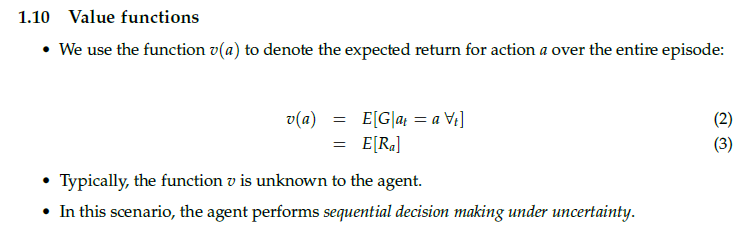

In [24]:
Image.open("C:/Admin/CQF Course/Module 5/Reinforcement Learning 1/rl_1.png")

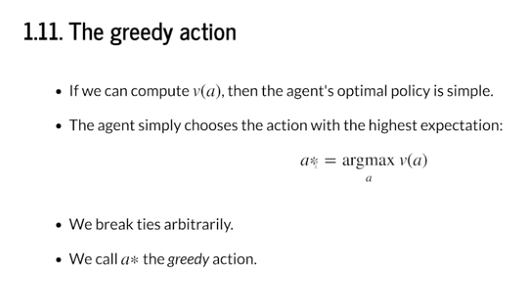

In [25]:
Image.open("C:/Admin/CQF Course/Module 5/Reinforcement Learning 1/rl_2.png")

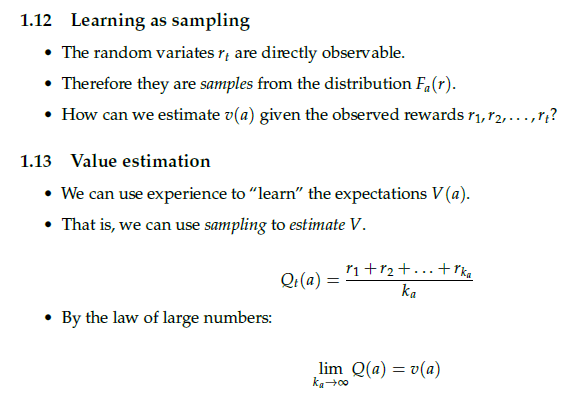

In [26]:
Image.open("C:/Admin/CQF Course/Module 5/Reinforcement Learning 1/rl_3.png")

### Value Estimation

In [ ]:
def sample_from_bandit(a,k):
    rewards = []
    for t in range(k):
        r = play_bandit(a)
        rewards.append(r)

    return np.mean(rewards)

# to sample  k= 20 times using action a=2
q_2 = sample_from_bandit(2,20)

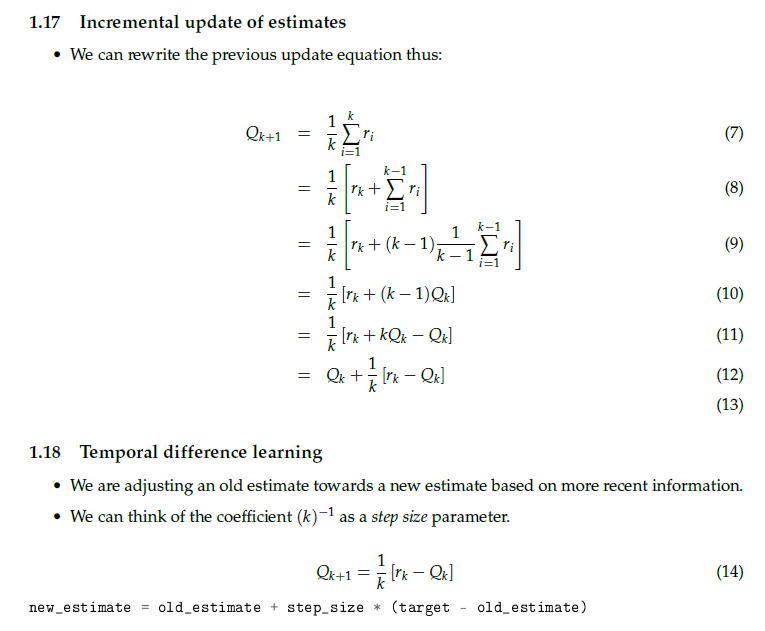

In [27]:
Image.open("C:/Admin/CQF Course/Module 5/Reinforcement Learning 1/rl_4.png")

In [ ]:
def update_q(old_estimate,target_estimate,k):
    step_size = 1/(k+1)
    error = target_estimate - old_estimate
    return old_estimate + step_size*(error)

def sample_from_bandit(a,k):

    current_estimate = 0
    for t in range(k):
        current_estimate = update_q(current_estimate,play_bandit(a),t)
    
    return  current_estimate
    

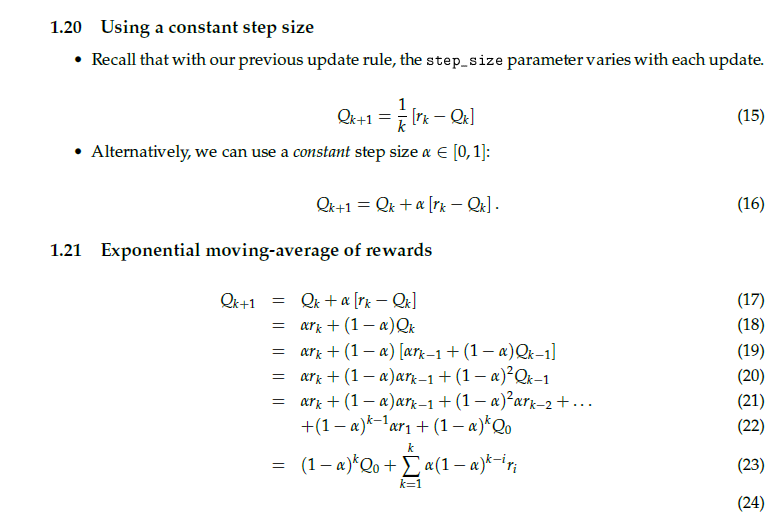

In [28]:
Image.open("C:/Admin/CQF Course/Module 5/Reinforcement Learning 1/rl_5.png")

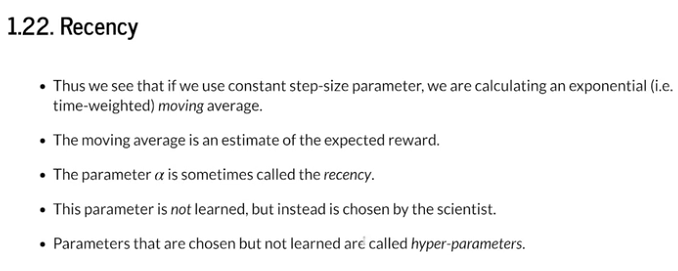

In [29]:
Image.open("C:/Admin/CQF Course/Module 5/Reinforcement Learning 1/rl_6.png")

In [54]:
# Non Stationary environment
# if the first moment of the reward distribution is non-stationary means mean is not constant i.e environemnt is changing rapidly.
# then we should use a large alpha means high weightage to recent observations.(can be seen from eq 18)

def update_q(old_estimate, target_estimate,recency = 0.2):
    error = target_estimate - old_estimate
    return old_estimate + recency*(error)
    

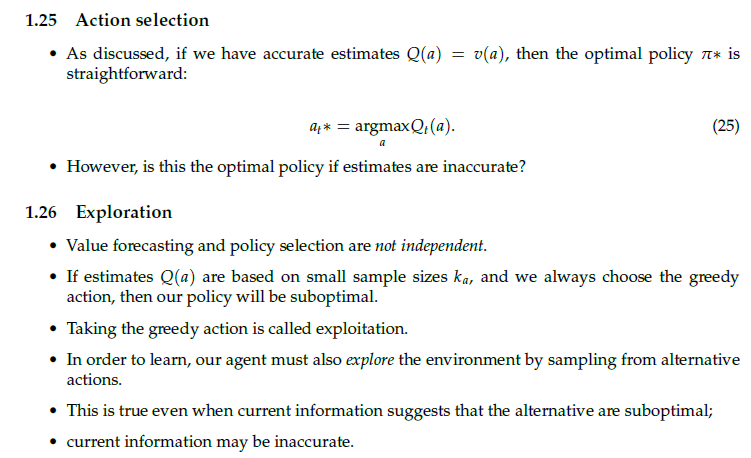

In [30]:
Image.open("C:/Admin/CQF Course/Module 5/Reinforcement Learning 1/rl_7.png")

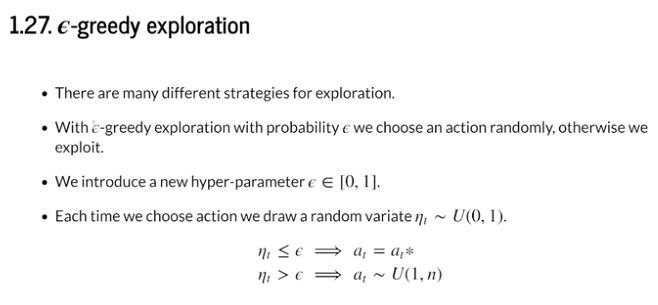

In [31]:
Image.open("C:/Admin/CQF Course/Module 5/Reinforcement Learning 1/rl_8.png")

#### epsilon greedy exploration

In [63]:
def explore(q):
    return np.random.randint(len(q))

def exploit(q):
    greedy_action, = np.where(q == np.max(q))              # this will give us index position in array
    return np.random.choice(greedy_action)                # break ties randomly
    
def act(q,epsilon= 0.99):
    if np.random.random() < epsilon:
        return exploit(q)
    else:
        return explore(q)

#### Complete Example

In [64]:
def simulate_agent(n=20, T=5000, epsilon=0.99, variance=1):
    q = np.zeros(n) ; actions = np.zeros(T) ; rewards = np.zeros(T)

    for t in range(T):
        a = act(q,epsilon)
        reward = play_bandit(a,variance)
        q[a] = update_q(q[a],reward)
        actions[t] = a
        rewards[t] = reward
    return q, actions, rewards 


q, actions, rewards = simulate_agent()   

#### time series of a_t

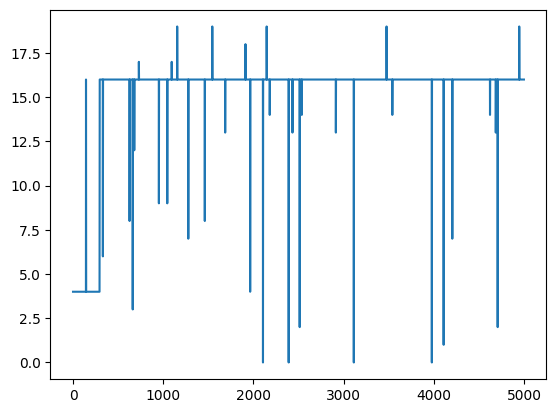

In [66]:
plt.plot(actions)
plt.show()

#### time series of rewards

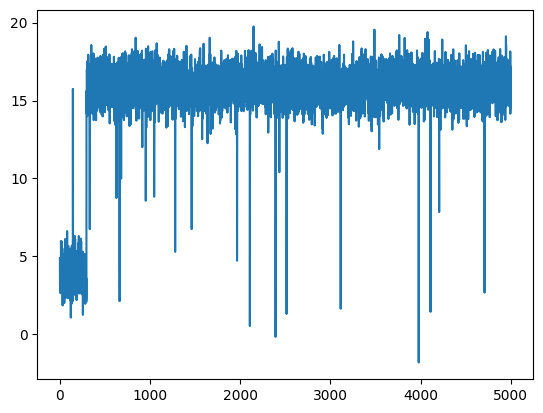

In [67]:
plt.plot(rewards)
plt.show()


### The exploration/exploitation trade-off

- Exploration can be costly since there is an opportunity-cost from not taking the greedy action;provided that our value estimates are accurate
- If estimates are inaccurate, we must explore in order to increase accuracy through sampling.
- if environment is very dynamic and then we can go for exploration and in cases of stable environments, we go for exploitation. 
- epsilon is exploration rate, in this example we took 1% as exploration.
- If we are certain about the rewards then there is no need to explore.
- Uncertainty can arise from:
(1) variance in the reward distributions, and
(2) non-stationarity in the underlying data-generation process for each reward distribution.
- Note that variance in reward distributions can be a modelling artifact;
- since sometimes we lack knowledge of, or the ability to control, extraneous variables which affect the reward
- This latter uncertaintity relates to the concept of states, which we discuss later


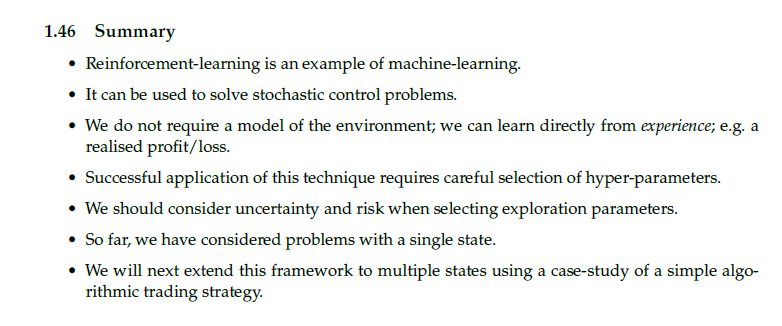

In [69]:
Image.open("C:/Admin/CQF Course/Module 5/Reinforcement Learning 1/rl_10.png")